In [75]:
import numpy as np
import pandas as pd

In [76]:
df = pd.read_csv('student_performance_raw.csv')

In [77]:
df

,student_id,age,gender,study_hours_per_day,attendance_percentage,previous_exam_score,internet_access,assignments_completed,teacher_remarks,final_exam_score
0,STU100000,20,Female,1.87,47.5,36.6,Yes,12,needs improvement,23.9
1,STU100001,17,Male,1.96,58.1,38.0,Yes,13,Work harder,39.9
2,STU100002,20,Female,0.26,40.3,9.0,Yes,13,needs improvement,3.0
3,STU100003,21,Male,2.17,58.4,-,Yes,15,Irregular attendance,24.3
4,STU100004,19,Male,5.49,80.7,40.8,NaN,19,Shows steady effort,51.5
...,...,...,...,...,...,...,...,...,...,...
100115,STU154706,19,Male,4.23,64.4,31.7,Yes,17,Shows steady effort,42.7
100116,STU156209,20,Female,2.28,43.6,1.8,Yes,14,often absent,12.4
100117,STU187018,17,Female,8.67,77.9,51.4,No,18,regular performer,63.4
100118,STU190260,22,Female,1.15,43.9,28.0,Yes,7,Work harder,19.6


In [78]:
df  = df.drop(columns=['student_id'])

In [79]:
df

,age,gender,study_hours_per_day,attendance_percentage,previous_exam_score,internet_access,assignments_completed,teacher_remarks,final_exam_score
0,20,Female,1.87,47.5,36.6,Yes,12,needs improvement,23.9
1,17,Male,1.96,58.1,38.0,Yes,13,Work harder,39.9
2,20,Female,0.26,40.3,9.0,Yes,13,needs improvement,3.0
3,21,Male,2.17,58.4,-,Yes,15,Irregular attendance,24.3
4,19,Male,5.49,80.7,40.8,NaN,19,Shows steady effort,51.5
...,...,...,...,...,...,...,...,...,...
100115,19,Male,4.23,64.4,31.7,Yes,17,Shows steady effort,42.7
100116,20,Female,2.28,43.6,1.8,Yes,14,often absent,12.4
100117,17,Female,8.67,77.9,51.4,No,18,regular performer,63.4
100118,22,Female,1.15,43.9,28.0,Yes,7,Work harder,19.6


In [80]:
df.isnull().sum()

age                      2755
gender                   3207
study_hours_per_day      2983
attendance_percentage    2661
previous_exam_score      2984
internet_access          2041
assignments_completed    2987
teacher_remarks          2990
final_exam_score         2715
dtype: int64

In [81]:
df.shape

(100120, 9)

In [82]:
df.head(3)

,age,gender,study_hours_per_day,attendance_percentage,previous_exam_score,internet_access,assignments_completed,teacher_remarks,final_exam_score
0,20,Female,1.87,47.5,36.6,Yes,12,needs improvement,23.9
1,17,Male,1.96,58.1,38.0,Yes,13,Work harder,39.9
2,20,Female,0.26,40.3,9.0,Yes,13,needs improvement,3.0


#  Basic Data Cleaning

In [83]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100120 entries, 0 to 100119
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   age                    97365 non-null  str  
 1   gender                 96913 non-null  str  
 2   study_hours_per_day    97137 non-null  str  
 3   attendance_percentage  97459 non-null  str  
 4   previous_exam_score    97136 non-null  str  
 5   internet_access        98079 non-null  str  
 6   assignments_completed  97133 non-null  str  
 7   teacher_remarks        97130 non-null  str  
 8   final_exam_score       97405 non-null  str  
dtypes: str(9)
memory usage: 11.2 MB


In [84]:
df['age']  = df['age'].str.replace("Unknown","")

In [85]:
df['age']  = df['age'].str.replace("-","")

In [86]:
df['age']   = pd.to_numeric(df['age'])

In [87]:
df.head(2)

,age,gender,study_hours_per_day,attendance_percentage,previous_exam_score,internet_access,assignments_completed,teacher_remarks,final_exam_score
0,20.0,Female,1.87,47.5,36.6,Yes,12,needs improvement,23.9
1,17.0,Male,1.96,58.1,38.0,Yes,13,Work harder,39.9


In [88]:
df['gender'].unique()

<ArrowStringArray>
[     'Female',        'Male',           nan,     'Unknown',           '-',
           'f',      'FEMALE',      ' male ',  'Non-binary',  'Non binary',
     'female ',           'M', ' non-binary',       'Other',        'MALE',
       'Femle']
Length: 16, dtype: str

In [89]:
gender_map = {
    'Female': 'Female',
    'female ': 'Female',
    'FEMALE': 'Female',
    'f': 'Female',
    'Femle': 'Female',
    'Male': 'Male',
    'MALE': 'Male',
    ' male ': 'Male',
    'M': 'Male',
    'Non-binary': 'Non-binary',
    'Non binary': 'Non-binary',
    ' non-binary': 'Non-binary',
    'Other': 'Other',
    'Unknown': 'Unknown',
    '-': 'Unknown'
}

df['gender'] = df['gender'].map(gender_map)

In [90]:
df['gender'].unique()

<ArrowStringArray>
['Female', 'Male', nan, 'Unknown', 'Non-binary', 'Other']
Length: 6, dtype: str

In [91]:
df.head(3)

,age,gender,study_hours_per_day,attendance_percentage,previous_exam_score,internet_access,assignments_completed,teacher_remarks,final_exam_score
0,20.0,Female,1.87,47.5,36.6,Yes,12,needs improvement,23.9
1,17.0,Male,1.96,58.1,38.0,Yes,13,Work harder,39.9
2,20.0,Female,0.26,40.3,9.0,Yes,13,needs improvement,3.0


In [92]:
df['study_hours_per_day'] = df['study_hours_per_day'].str.replace("-","")

In [93]:
df['study_hours_per_day'] = df['study_hours_per_day'].str.replace("Not Available","")
# df['study_hours_per_day']= pd.to_numeric(df['study_hours_per_day'])

In [94]:
df['study_hours_per_day']= pd.to_numeric(df['study_hours_per_day'])

In [95]:
df.head(3)

,age,gender,study_hours_per_day,attendance_percentage,previous_exam_score,internet_access,assignments_completed,teacher_remarks,final_exam_score
0,20.0,Female,1.87,47.5,36.6,Yes,12,needs improvement,23.9
1,17.0,Male,1.96,58.1,38.0,Yes,13,Work harder,39.9
2,20.0,Female,0.26,40.3,9.0,Yes,13,needs improvement,3.0


In [96]:
# df['attendance_percentage'].unique()
# df['attendance_percentage'] = pd.to_numeric(df['attendance_percentage'])
df['attendance_percentage'] = df['attendance_percentage'].str.replace('Unknown',"")
df['attendance_percentage'] = df['attendance_percentage'].str.replace('-',"")

In [97]:
df['attendance_percentage'] = pd.to_numeric(df['attendance_percentage'])

In [98]:
df.head(2)

,age,gender,study_hours_per_day,attendance_percentage,previous_exam_score,internet_access,assignments_completed,teacher_remarks,final_exam_score
0,20.0,Female,1.87,47.5,36.6,Yes,12,needs improvement,23.9
1,17.0,Male,1.96,58.1,38.0,Yes,13,Work harder,39.9


In [99]:
# df['previous_exam_score'].value_counts()
df['previous_exam_score'] = df['previous_exam_score'].str.replace("Not Available","")
df['previous_exam_score'] = df['previous_exam_score'].str.replace("-","")

In [100]:
df['previous_exam_score']  = pd.to_numeric(df['previous_exam_score'])

In [101]:
df['internet_access'].unique()

<ArrowStringArray>
[     'Yes',        nan,       'No',        '-',        'N',  'Unknown',
     ' No ',        'y',      'yes',       'NO', 'Unknown ',        'Y',
        'n',      'YES',  'unknown']
Length: 15, dtype: str

In [102]:
df['internet_access'] = df['internet_access'].str.strip().str.lower()

value_map = {
    'yes': 'Yes',
    'y': 'Yes',
    'no': 'No',
    'n': 'No',
    'unknown': 'Unknown',
    '-': 'Unknown'
}

df['internet_access'] = df['internet_access'].map(value_map)

In [103]:
df.tail()

,age,gender,study_hours_per_day,attendance_percentage,previous_exam_score,internet_access,assignments_completed,teacher_remarks,final_exam_score
100115,19.0,Male,4.23,64.4,31.7,Yes,17,Shows steady effort,42.7
100116,20.0,Female,2.28,43.6,1.8,Yes,14,often absent,12.4
100117,17.0,Female,8.67,77.9,51.4,No,18,regular performer,63.4
100118,22.0,Female,1.15,43.9,28.0,Yes,7,Work harder,19.6
100119,19.0,Female,1.76,63.7,27.4,Yes,13,needs improvement,31.1


In [104]:
df['assignments_completed'] = df['assignments_completed'].str.replace('Not Available',"")

In [105]:
df['assignments_completed'] = df['assignments_completed'].str.replace('-',"")

In [106]:
df['assignments_completed'] = pd.to_numeric(df['assignments_completed'])

In [107]:
df.head(3)

,age,gender,study_hours_per_day,attendance_percentage,previous_exam_score,internet_access,assignments_completed,teacher_remarks,final_exam_score
0,20.0,Female,1.87,47.5,36.6,Yes,12.0,needs improvement,23.9
1,17.0,Male,1.96,58.1,38.0,Yes,13.0,Work harder,39.9
2,20.0,Female,0.26,40.3,9.0,Yes,13.0,needs improvement,3.0


### EDA(Explorty Data Analysis)

In [108]:
df.head(2)

,age,gender,study_hours_per_day,attendance_percentage,previous_exam_score,internet_access,assignments_completed,teacher_remarks,final_exam_score
0,20.0,Female,1.87,47.5,36.6,Yes,12.0,needs improvement,23.9
1,17.0,Male,1.96,58.1,38.0,Yes,13.0,Work harder,39.9


In [109]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [110]:
pd.set_option("display.max_columns",None)

### Dataset Structure

In [111]:
df.shape

(100120, 9)

In [112]:
df.columns

Index(['age', 'gender', 'study_hours_per_day', 'attendance_percentage',
       'previous_exam_score', 'internet_access', 'assignments_completed',
       'teacher_remarks', 'final_exam_score'],
      dtype='str')

In [113]:
df.dtypes

age                      float64
gender                       str
study_hours_per_day      float64
attendance_percentage    float64
previous_exam_score      float64
internet_access              str
assignments_completed    float64
teacher_remarks              str
final_exam_score             str
dtype: object

In [114]:
df.head(8)

,age,gender,study_hours_per_day,attendance_percentage,previous_exam_score,internet_access,assignments_completed,teacher_remarks,final_exam_score
0,20.0,Female,1.87,47.5,36.6,Yes,12.0,needs improvement,23.9
1,17.0,Male,1.96,58.1,38.0,Yes,13.0,Work harder,39.9
2,20.0,Female,0.26,40.3,9.0,Yes,13.0,needs improvement,3.0
3,21.0,Male,2.17,58.4,NaN,Yes,15.0,Irregular attendance,24.3
4,19.0,Male,5.49,80.7,40.8,NaN,19.0,Shows steady effort,51.5
5,18.0,Female,1.87,66.3,31.4,No,17.0,often absent,33.1
6,18.0,Male,0.79,50.5,17.8,Yes,14.0,Not Available,25.7
7,21.0,NaN,3.10,71.0,39.3,Yes,16.0,NaN,54.8


In [115]:
df.duplicated().sum()

np.int64(120)

### Observation:
Dataset Cantain missing vlaue and negative value also duplicates values

### Data Quality

In [116]:
# Missing value count
print(df.isnull().sum())

# Missing value percentage
missing_percent = (df.isnull().sum() / len(df)) * 100

print(missing_percent.sort_values(ascending=False))

age                      4503
gender                   3207
study_hours_per_day      5006
attendance_percentage    4502
previous_exam_score      5005
internet_access          2041
assignments_completed    5003
teacher_remarks          2990
final_exam_score         2715
dtype: int64
study_hours_per_day      5.000000
previous_exam_score      4.999001
assignments_completed    4.997004
age                      4.497603
attendance_percentage    4.496604
gender                   3.203156
teacher_remarks          2.986416
final_exam_score         2.711746
internet_access          2.038554
dtype: float64


In [117]:
missing_percent[missing_percent > 0]

age                      4.497603
gender                   3.203156
study_hours_per_day      5.000000
attendance_percentage    4.496604
previous_exam_score      4.999001
internet_access          2.038554
assignments_completed    4.997004
teacher_remarks          2.986416
final_exam_score         2.711746
dtype: float64

### Checking Invalid Range

In [118]:
# # Check age outside a reasonable range
# print(df[(df['age'] < 0) | (df['age'] > 100)])

# # Check marks outside the valid range
# print(df[(df['final_exam_score'] < 0) | (df['final_exam_score'] > 100)])

In [119]:
df['final_exam_score'] = df['final_exam_score'].str.replace("Not Available","")


In [120]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100120 entries, 0 to 100119
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   age                    95617 non-null  float64
 1   gender                 96913 non-null  str    
 2   study_hours_per_day    95114 non-null  float64
 3   attendance_percentage  95618 non-null  float64
 4   previous_exam_score    95115 non-null  float64
 5   internet_access        98079 non-null  str    
 6   assignments_completed  95117 non-null  float64
 7   teacher_remarks        97130 non-null  str    
 8   final_exam_score       97405 non-null  str    
dtypes: float64(5), str(4)
memory usage: 9.6 MB


In [121]:
df['final_exam_score'] = df['final_exam_score'].str.replace("-","")

In [122]:
df['final_exam_score'] = pd.to_numeric(df['final_exam_score'])

In [123]:
# Check age outside a reasonable range
df = df[(df['age'] > 0) | (df['age'] < 100)]
# Check marks outside the valid range
df = df[(df['final_exam_score'] > 0) | (df['final_exam_score'] < 100)]

In [124]:
df.shape

(91285, 9)

### For automatic inspection of numerical ranges:

In [125]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
age,91285.0,19.547275,3.868205,0.00,18.0,19.00,21.00,999.0
study_hours_per_day,86719.0,3.546729,2.101753,0.05,2.0,3.15,4.69,99.0
attendance_percentage,87176.0,63.942414,15.713657,0.00,53.4,63.60,74.20,999.0
previous_exam_score,86713.0,35.963197,16.379976,0.00,24.8,35.60,46.60,999.0
assignments_completed,86736.0,14.634984,4.295951,1.00,13.0,15.00,17.00,999.0
final_exam_score,91285.0,37.474686,17.366396,0.00,25.5,36.60,48.50,999.0


## Check unique values

In [126]:
print(df.nunique(dropna=False).sort_values())

internet_access            4
gender                     6
assignments_completed     25
age                       25
teacher_remarks           30
attendance_percentage    812
previous_exam_score      939
study_hours_per_day      958
final_exam_score         983
dtype: int64


### Inspect all categories in a particular column:

In [127]:
print(df['gender'].unique())
print(df['gender'].value_counts(dropna=False))

<ArrowStringArray>
['Female', 'Male', nan, 'Unknown', 'Non-binary', 'Other']
Length: 6, dtype: str
gender
Male          43569
Female        40506
NaN            2935
Non-binary     2085
Unknown        1973
Other           217
Name: count, dtype: int64


In [130]:
print(df['teacher_remarks'].unique())
print(df['teacher_remarks'].value_counts(dropna=False))

<ArrowStringArray>
[            'needs improvement',                   'Work harder',
          'Irregular attendance',           'Shows steady effort',
                  'often absent',                 'Not Available',
                             nan,            'regular performer ',
           'Average performance', 'Assignments completed on time',
     'Can improve with practice',         'Satisfactory progress',
             'regular performer',            'EXCELLENT PROGRESS',
                       'Unknown',                    'wrk harder',
        '  Excellent progress  ',       '  satisfactory PROGRESS',
              'good progress!!!',          'Consistant performer',
                   'Often absnt',          'consistent performer',
            'Excellent progress',                             '-',
            'Strong improvement',             'NEEDS IMPROVEMENT',
      'Good class participation',              'needs improvment',
                'Always present',          

In [ ]:
# df['teacher_remarks'] = df['teacher_remarks'].str.strip()
# df['teacher_remarks'] = df['teacher_remarks'].str.replace("-","")

In [135]:
df = df.drop(columns=['teacher_remarks'])

In [136]:
cat_cols = df.select_dtypes(
    include=['object', 'string', 'category']
).columns

for col in cat_cols:
    print(f"\nColumn: {col}")
    print(df[col].value_counts(dropna=False).head(30))


Column: gender
gender
Male          43569
Female        40506
NaN            2935
Non-binary     2085
Unknown        1973
Other           217
Name: count, dtype: int64

Column: internet_access
internet_access
Yes        68232
No         19348
Unknown     1871
NaN         1834
Name: count, dtype: int64


### Check category consistency

In [137]:
for col in cat_cols:
    print(f"\nColumn: {col}")
    print(df[col].dropna().unique())


Column: gender
<ArrowStringArray>
['Female', 'Male', 'Unknown', 'Non-binary', 'Other']
Length: 5, dtype: str

Column: internet_access
<ArrowStringArray>
['Yes', 'No', 'Unknown']
Length: 3, dtype: str


In [138]:
for col in cat_cols:
    df[col] = df[col].str.strip().str.lower()

In [139]:
# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# View duplicate rows
df[df.duplicated(keep=False)]

Duplicate rows: 114


,age,gender,study_hours_per_day,attendance_percentage,previous_exam_score,internet_access,assignments_completed,final_exam_score
33,19.0,female,4.49,68.6,16.5,yes,11.0,36.7
1199,20.0,non-binary,2.00,76.3,31.4,no,18.0,50.6
2118,19.0,female,NaN,54.7,NaN,no,10.0,32.0
2223,20.0,NaN,2.45,40.3,31.4,yes,12.0,34.8
2272,21.0,female,3.40,55.2,34.1,yes,12.0,27.7
...,...,...,...,...,...,...,...,...
100115,19.0,male,4.23,64.4,31.7,yes,17.0,42.7
100116,20.0,female,2.28,43.6,1.8,yes,14.0,12.4
100117,17.0,female,8.67,77.9,51.4,no,18.0,63.4
100118,22.0,female,1.15,43.9,28.0,yes,7.0,19.6


In [140]:
quality_report = pd.DataFrame({
    'Data Type': df.dtypes.astype(str),
    'Missing Count': df.isnull().sum(),
    'Missing %': (df.isnull().sum() / len(df) * 100).round(2),
    'Unique Values': df.nunique(dropna=False),
    'Duplicate Count': [
        df[col].duplicated().sum()
        for col in df.columns
    ]
})

quality_report.sort_values(
    by='Missing %',
    ascending=False
)

,Data Type,Missing Count,Missing %,Unique Values,Duplicate Count
previous_exam_score,float64,4572,5.01,939,90346
study_hours_per_day,float64,4566,5.00,958,90327
assignments_completed,float64,4549,4.98,25,91260
attendance_percentage,float64,4109,4.50,812,90473
gender,str,2935,3.22,6,91279
internet_access,str,1834,2.01,4,91281
age,float64,0,0.00,25,91260
final_exam_score,float64,0,0.00,983,90302


### Target Analysis

### . Calculate mean, median, and spread

In [141]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

scores = pd.to_numeric(df['final_exam_score'], errors='coerce').dropna()

print("Mean:", scores.mean())
print("Median:", scores.median())
print("Minimum:", scores.min())
print("Maximum:", scores.max())
print("Range:", scores.max() - scores.min())
print("Standard Deviation:", scores.std())
print("Variance:", scores.var())
print("25th Percentile (Q1):", scores.quantile(0.25))
print("75th Percentile (Q3):", scores.quantile(0.75))
print("IQR:", scores.quantile(0.75) - scores.quantile(0.25))

Mean: 37.474685873911376
Median: 36.6
Minimum: 0.0
Maximum: 999.0
Range: 999.0
Standard Deviation: 17.36639577475409
Variance: 301.5917022053967
25th Percentile (Q1): 25.5
75th Percentile (Q3): 48.5
IQR: 23.0


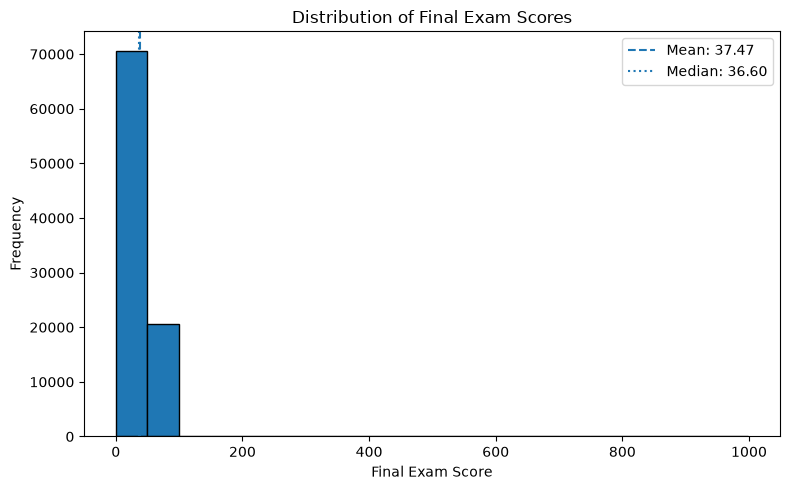

In [142]:
plt.figure(figsize=(8, 5))

plt.hist(scores, bins=20, edgecolor='black')

plt.axvline(scores.mean(), linestyle='--',
            label=f'Mean: {scores.mean():.2f}')

plt.axvline(scores.median(), linestyle=':',
            label=f'Median: {scores.median():.2f}')

plt.title('Distribution of Final Exam Scores')
plt.xlabel('Final Exam Score')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

### Detect outliers using IQR

In [143]:
Q1 = scores.quantile(0.25)
Q3 = scores.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = scores[
    (scores < lower_bound) |
    (scores > upper_bound)
]

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(outliers))
print("Outlier Percentage:", round(len(outliers) / len(scores) * 100, 2), "%")
print(outliers)

Lower Bound: -9.0
Upper Bound: 83.0
Number of Outliers: 607
Outlier Percentage: 0.66 %
163       95.8
168      105.0
246       85.5
445       86.1
639       84.0
         ...  
98919     94.0
99045     93.2
99499    101.0
99507     86.7
99591     89.1
Name: final_exam_score, Length: 607, dtype: float64


C:\Users\mdsal\AppData\Local\Temp\ipykernel_14892\944251505.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(scores, vert=False)


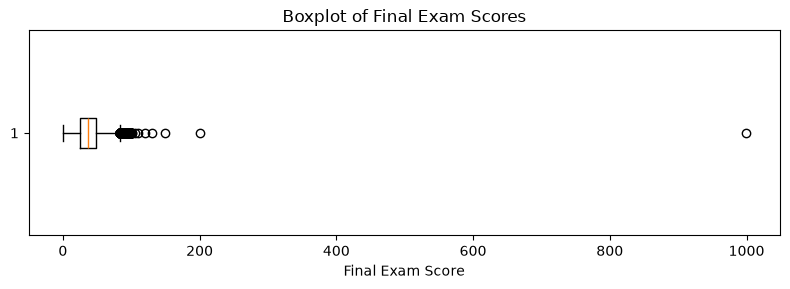

In [144]:
plt.figure(figsize=(8, 3))

plt.boxplot(scores, vert=False)

plt.title('Boxplot of Final Exam Scores')
plt.xlabel('Final Exam Score')
plt.tight_layout()
plt.show()

In [145]:
target_summary = pd.DataFrame({
    'Metric': [
        'Count', 'Mean', 'Median', 'Standard Deviation',
        'Minimum', 'Maximum', 'Range', 'Q1', 'Q3', 'IQR',
        'Outlier Count'
    ],
    'Value': [
        scores.count(), scores.mean(), scores.median(),
        scores.std(), scores.min(), scores.max(),
        scores.max() - scores.min(), Q1, Q3, IQR,
        len(outliers)
    ]
})

target_summary

,Metric,Value
0,Count,91285.000000
1,Mean,37.474686
2,Median,36.600000
3,Standard Deviation,17.366396
4,Minimum,0.000000
5,Maximum,999.000000
6,Range,999.000000
7,Q1,25.500000
8,Q3,48.500000
9,IQR,23.000000


### Numerical relationships

In [148]:
df.head()

,age,gender,study_hours_per_day,attendance_percentage,previous_exam_score,internet_access,assignments_completed,final_exam_score
0,20.0,female,1.87,47.5,36.6,yes,12.0,23.9
1,17.0,male,1.96,58.1,38.0,yes,13.0,39.9
2,20.0,female,0.26,40.3,9.0,yes,13.0,3.0
3,21.0,male,2.17,58.4,NaN,yes,15.0,24.3
4,19.0,male,5.49,80.7,40.8,NaN,19.0,51.5


### Scatter plots

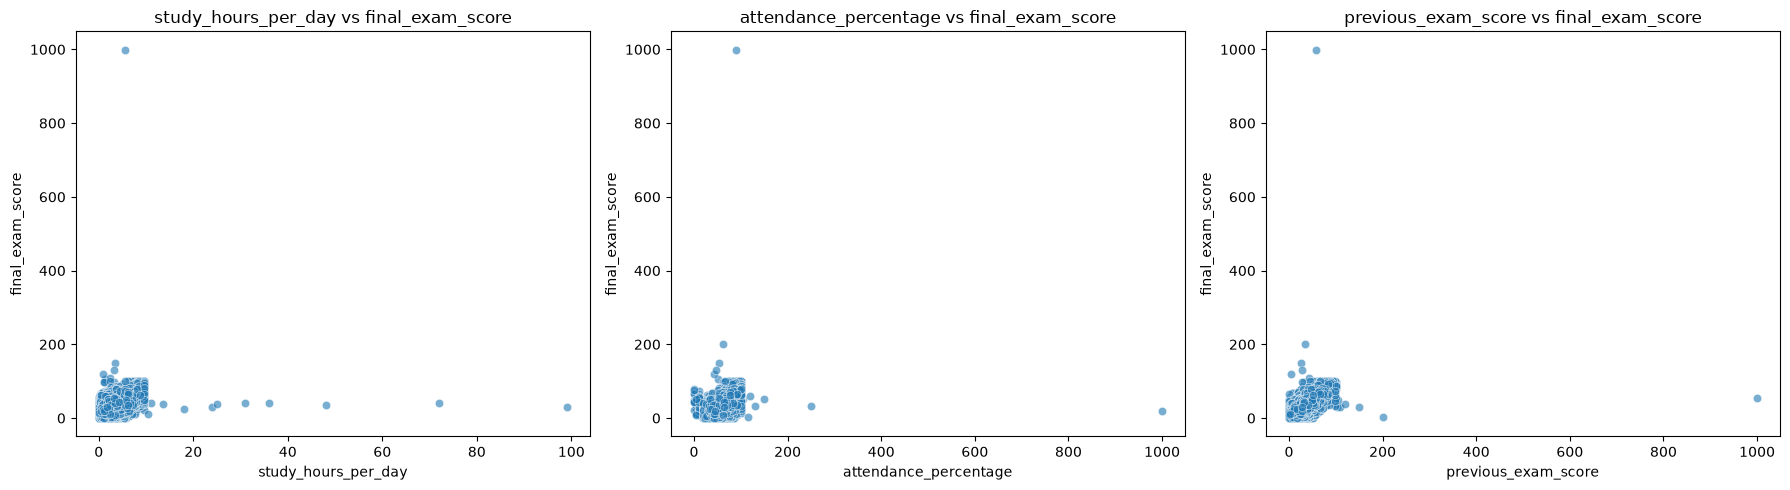

In [149]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

features = [
    'study_hours_per_day',
    'attendance_percentage',
    'previous_exam_score'
]

target = 'final_exam_score'

# Convert columns to numeric
data = df[features + [target]].apply(
    pd.to_numeric, errors='coerce'
)

# Create scatter plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, features):
    sns.scatterplot(
        data=data,
        x=col,
        y=target,
        ax=ax,
        alpha=0.6
    )
    ax.set_title(f'{col} vs {target}')

plt.tight_layout()
plt.show()

### Correlation analysis

In [150]:
correlation = data.corr()

print(
    correlation['final_exam_score']
    .drop('final_exam_score')
    .sort_values(ascending=False)
)

previous_exam_score      0.655766
study_hours_per_day      0.623264
attendance_percentage    0.580856
Name: final_exam_score, dtype: float64


## Obervation:
This tells you which feature has the strongest positive or negative linear relationship with the final exam score.

### Correlation heatmap

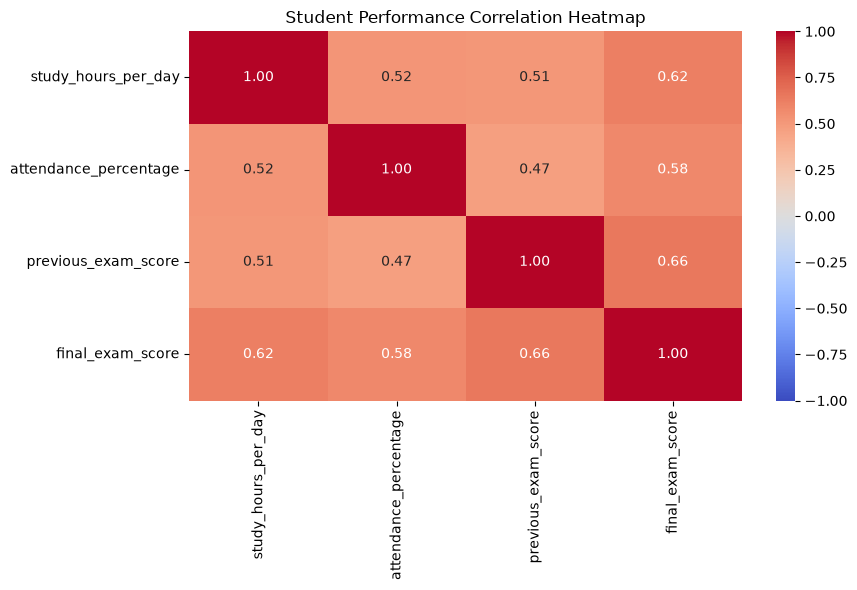

In [151]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Student Performance Correlation Heatmap')
plt.tight_layout()
plt.show()

## Check relationships between input features

In [152]:
input_corr = data[features].corr()

print(input_corr)

                       study_hours_per_day  attendance_percentage  \
study_hours_per_day               1.000000               0.522592   
attendance_percentage             0.522592               1.000000   
previous_exam_score               0.514560               0.473053   

                       previous_exam_score  
study_hours_per_day               0.514560  
attendance_percentage             0.473053  
previous_exam_score               1.000000  


### Compare scores by gender, internet access, and teacher remarks

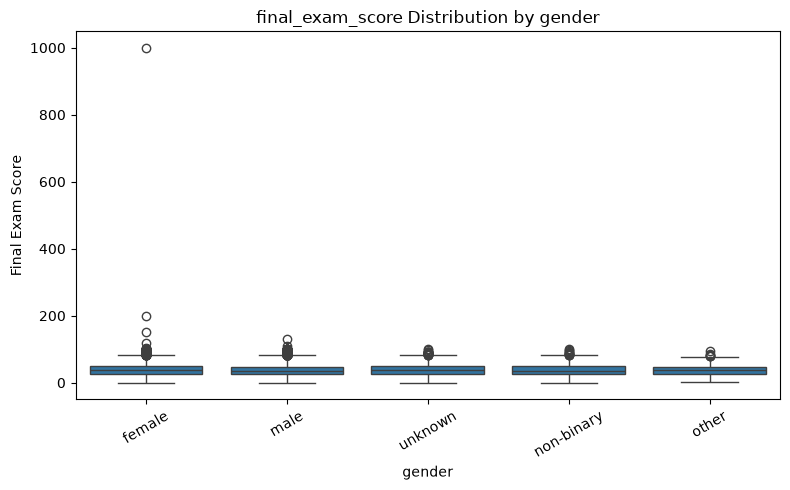

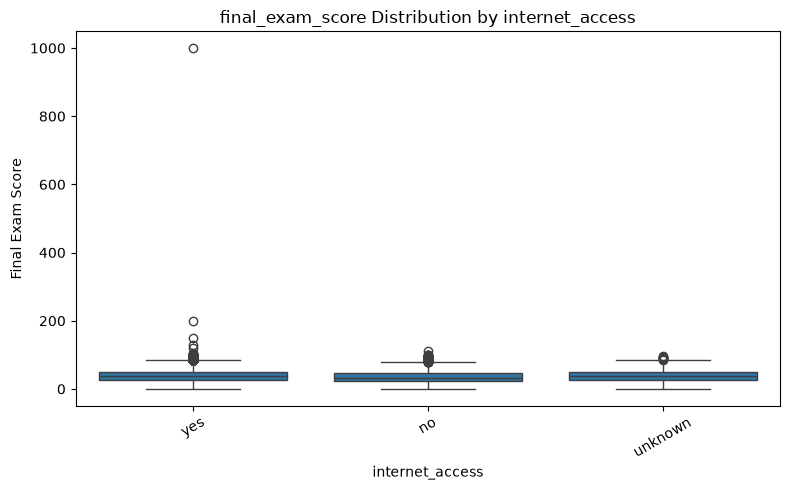

Skipping teacher_remarks: column not found


In [153]:
import matplotlib.pyplot as plt
import seaborn as sns

target = 'final_exam_score'

categorical_cols = [
    'gender',
    'internet_access',
    'teacher_remarks'
]

for col in categorical_cols:
    if col not in df.columns:
        print(f"Skipping {col}: column not found")
        continue

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x=col,
        y=target
    )

    plt.title(f'{target} Distribution by {col}')
    plt.xlabel(col)
    plt.ylabel('Final Exam Score')
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

### 2. Compare average and median scores

In [154]:
for col in categorical_cols:
    if col not in df.columns:
        continue

    summary = df.groupby(col, dropna=False)[target].agg(
        ['count', 'mean', 'median', 'std', 'min', 'max']
    ).round(2)

    print(f'\nScore comparison by {col}:')
    print(summary)


Score comparison by gender:
            count   mean  median    std  min    max
gender                                             
female      40506  37.77    36.9  17.74  0.0  999.0
male        43569  37.20    36.4  17.02  0.0  130.0
non-binary   2085  37.40    36.5  16.93  0.0   99.7
other         217  37.30    36.9  17.20  0.8   95.4
unknown      1973  37.83    37.2  17.19  0.0  100.0
NaN          2935  37.43    36.7  17.53  0.0  100.0

Score comparison by internet_access:
                 count   mean  median    std  min    max
internet_access                                         
no               19348  34.39    33.4  16.94  0.0  110.0
unknown           1871  37.64    37.0  17.26  0.0   96.2
yes              68232  38.32    37.5  17.40  0.0  999.0
NaN               1834  38.42    38.2  17.08  0.0   99.1


## Plot average scores by category

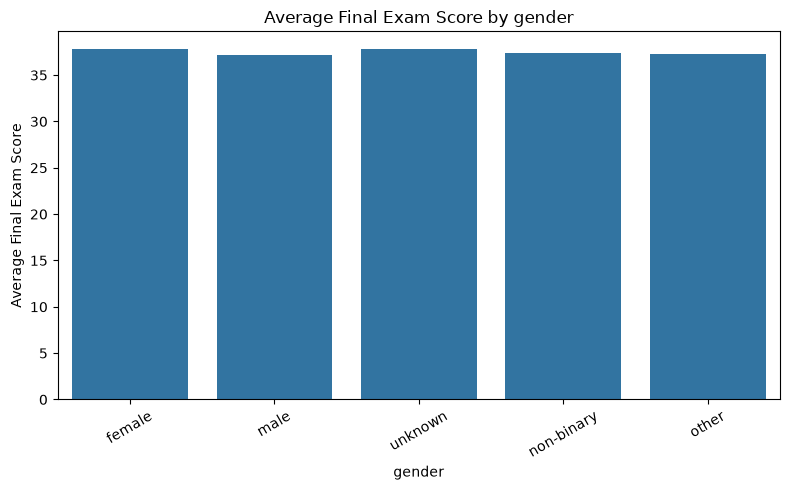

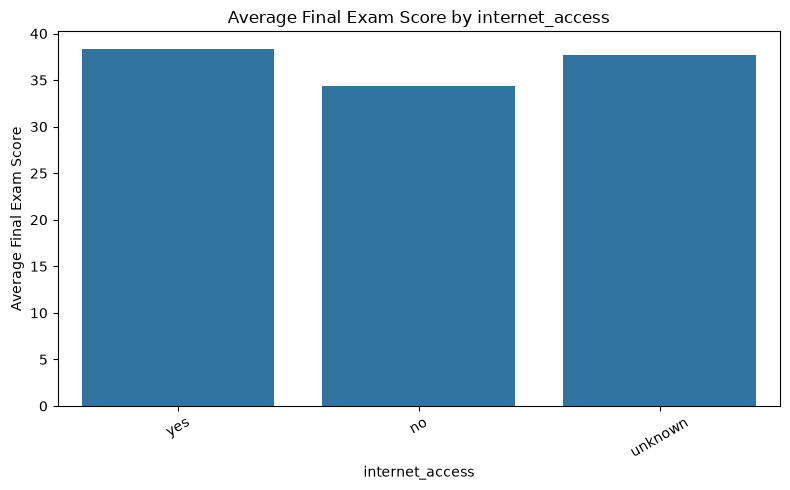

In [155]:
for col in categorical_cols:
    if col not in df.columns:
        continue

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=df,
        x=col,
        y=target,
        errorbar=None
    )

    plt.title(f'Average Final Exam Score by {col}')
    plt.xlabel(col)
    plt.ylabel('Average Final Exam Score')
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

###  Multicollinearity

In [156]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

predictors = [
    'study_hours_per_day',
    'attendance_percentage',
    'previous_exam_score'
]

X = df[predictors].apply(pd.to_numeric, errors='coerce')

correlation_matrix = X.corr()

print(correlation_matrix.round(2))

                       study_hours_per_day  attendance_percentage  \
study_hours_per_day                   1.00                   0.52   
attendance_percentage                 0.52                   1.00   
previous_exam_score                   0.51                   0.47   

                       previous_exam_score  
study_hours_per_day                   0.51  
attendance_percentage                 0.47  
previous_exam_score                   1.00  


### Visualize correlations using a heatmap

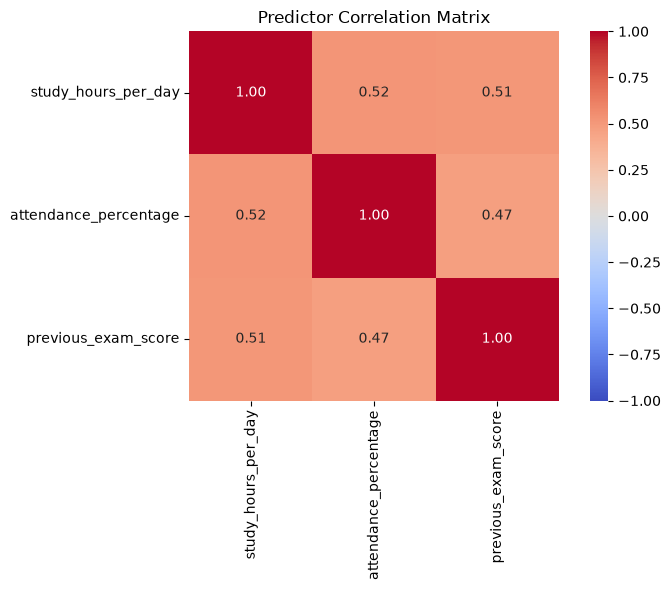

In [157]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    square=True
)

plt.title('Predictor Correlation Matrix')
plt.tight_layout()
plt.show()

Interpret the correlation coefficient:

Absolute correlation	Interpretation

0.00–0.30	Weak relationship

0.30–0.70	Moderate relationship

0.70–0.90	Strong relationship

0.90–1.00	Very strong relationship

### Automatically identify highly correlated pairs

In [158]:
import numpy as np

threshold = 0.80

upper_triangle = correlation_matrix.abs().where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

high_corr_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_corr_pairs.columns = [
    'Feature 1',
    'Feature 2',
    'Absolute Correlation'
]

high_corr_pairs = high_corr_pairs[
    high_corr_pairs['Absolute Correlation'] >= threshold
]

print(high_corr_pairs)

Empty DataFrame
Columns: [Feature 1, Feature 2, Absolute Correlation]
Index: []


Check multicollinearity using VIF
Correlation checks only pairs of features. Variance Inflation Factor (VIF) can help detect whether a predictor is explained by a combination of the other predictors.

In [159]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = X.dropna()

vif_df = pd.DataFrame({
    'Feature': X_vif.columns,
    'VIF': [
        variance_inflation_factor(
            X_vif.values, i
        )
        for i in range(X_vif.shape[1])
    ]
})

print(vif_df.sort_values('VIF', ascending=False))

                 Feature       VIF
1  attendance_percentage  9.004564
2    previous_exam_score  8.407375
0    study_hours_per_day  5.877166


In [160]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


General interpretation:
- VIF near 1: Little linear redundancy.
- VIF above 5: Potential concern worth investigating.
- VIF above 10: Often considered substantial multicollinearity.
These thresholds are guidelines, not automatic rules for removing features

### Leakage check

## Check whether teacher_remarks exists

In [161]:
print(df.columns.tolist())

if 'teacher_remarks' in df.columns:
    print(df['teacher_remarks'].value_counts(dropna=False))
else:
    print("teacher_remarks column not found")


['age', 'gender', 'study_hours_per_day', 'attendance_percentage', 'previous_exam_score', 'internet_access', 'assignments_completed', 'final_exam_score']
teacher_remarks column not found


## Compare teacher remarks with final scores

In [162]:
import pandas as pd

if 'teacher_remarks' in df.columns:
    print(
        df.groupby('teacher_remarks', dropna=False)[
            'final_exam_score'
        ].agg(['count', 'mean', 'median', 'min', 'max'])
    )

## Check whether remarks are derived directly from scores

Final decision: Should you use teacher remarks?
When remarks are created	Decision
Before the final exam, using prior observations	May be usable
Directly from the final exam score	Exclude
After the final exam, using teacher evaluation of results	Usually exclude for pre-exam prediction
Creation timing or rules are unknown	Exclude initially until verified

In [168]:
df.to_csv("EDA_Completed.csv")